Downloaded 500 return points.



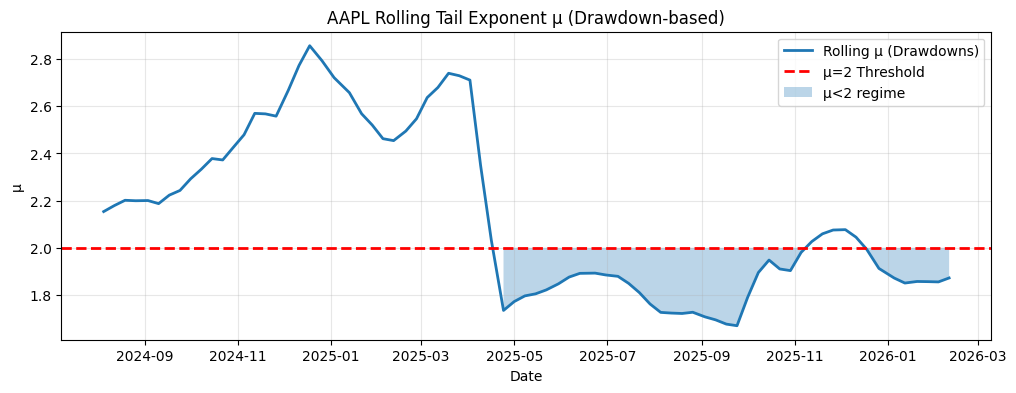

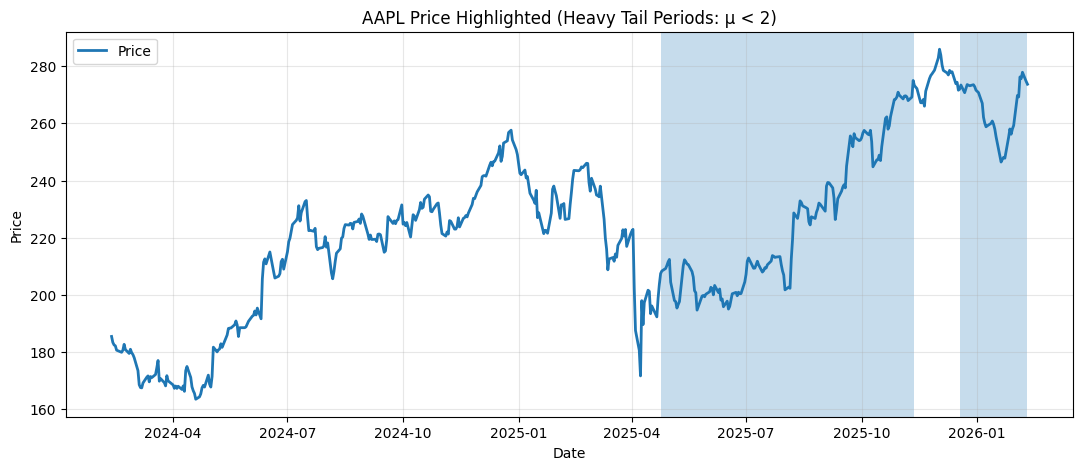

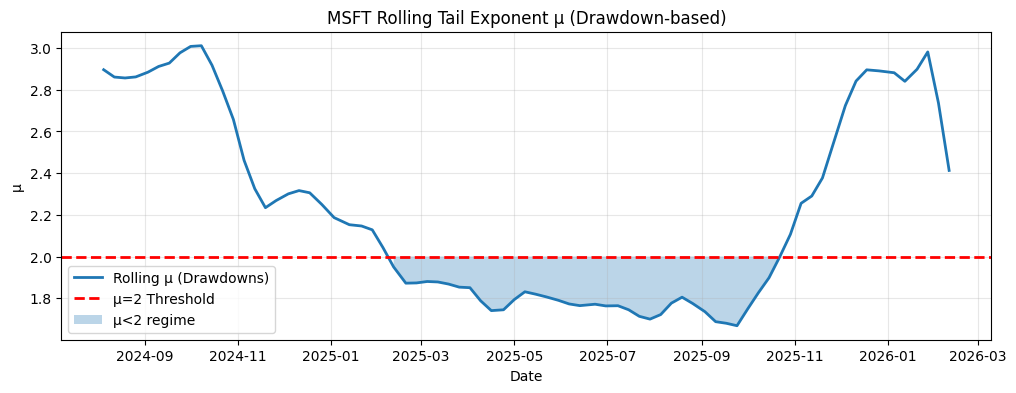

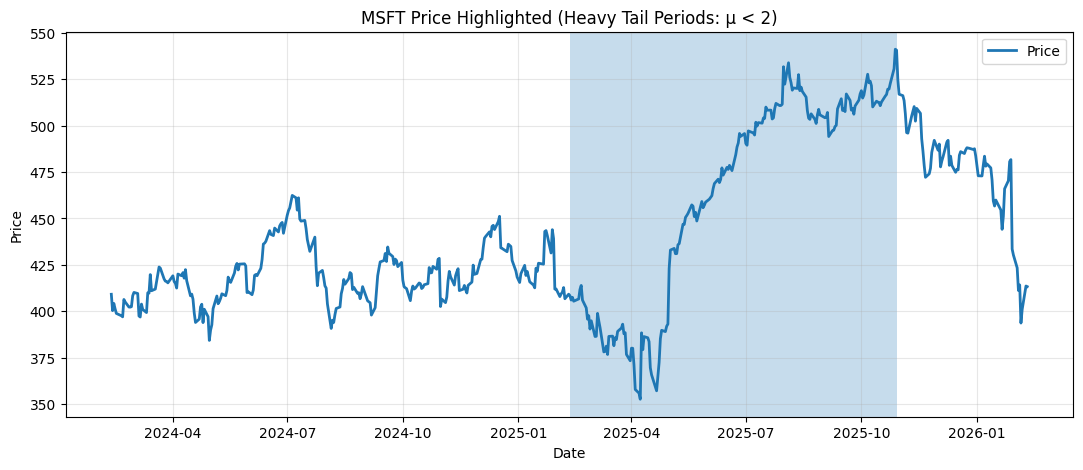

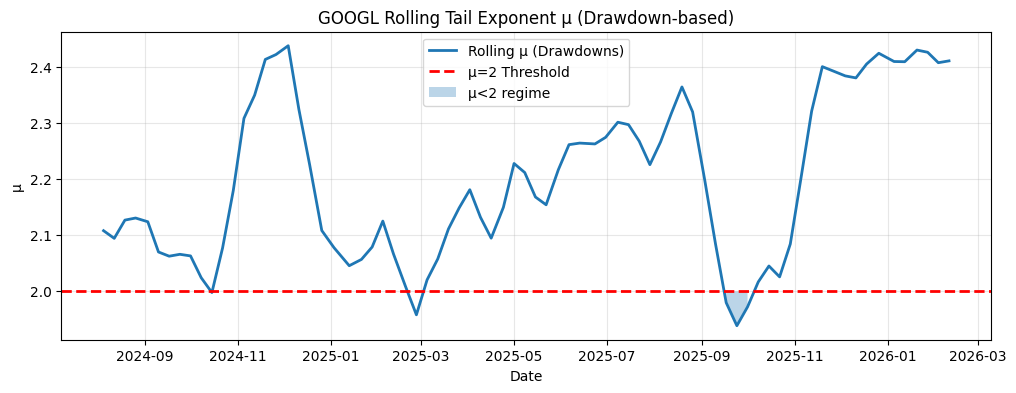

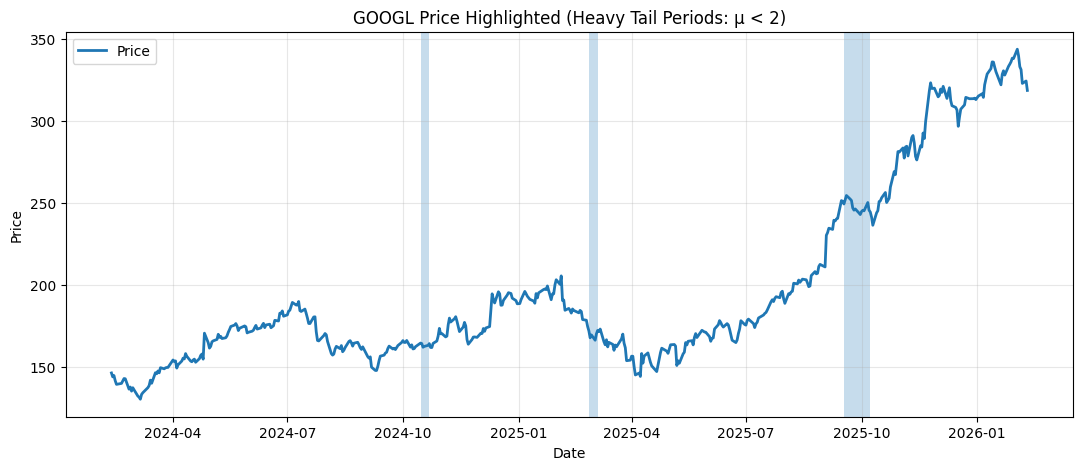

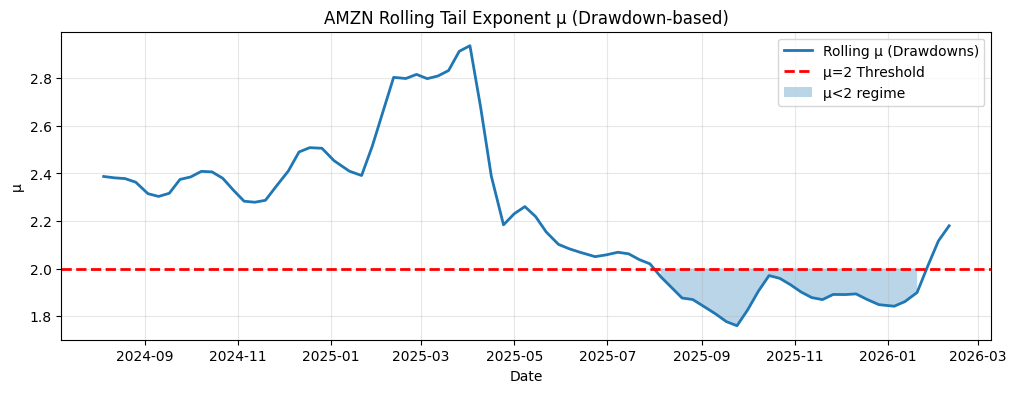

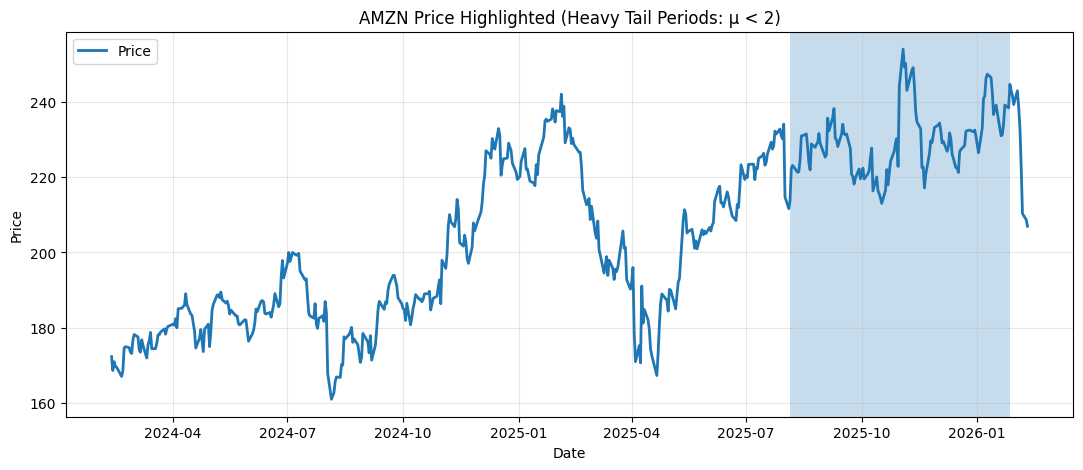

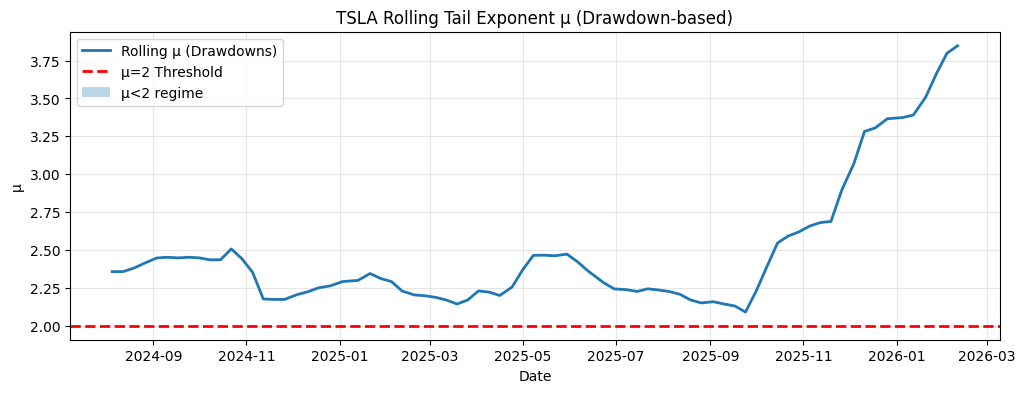

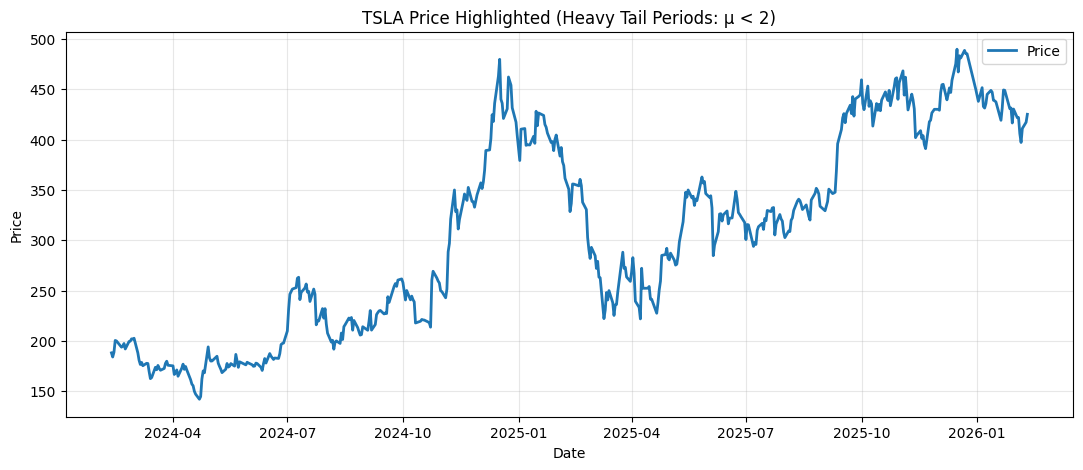

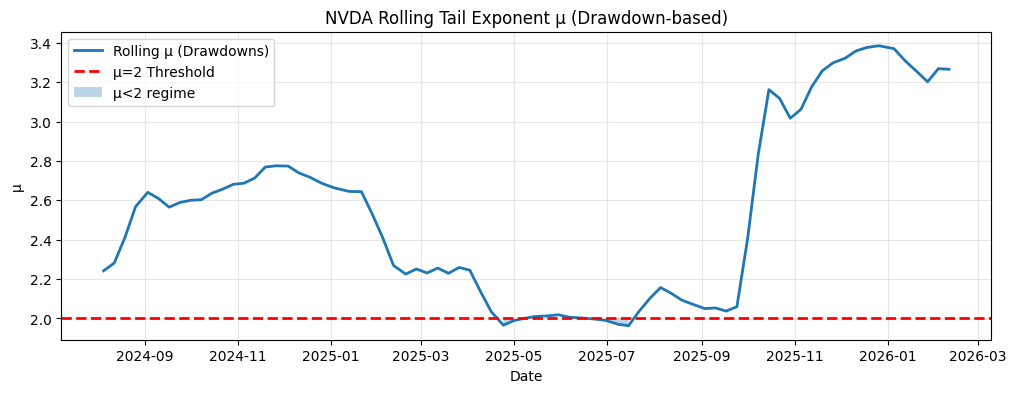

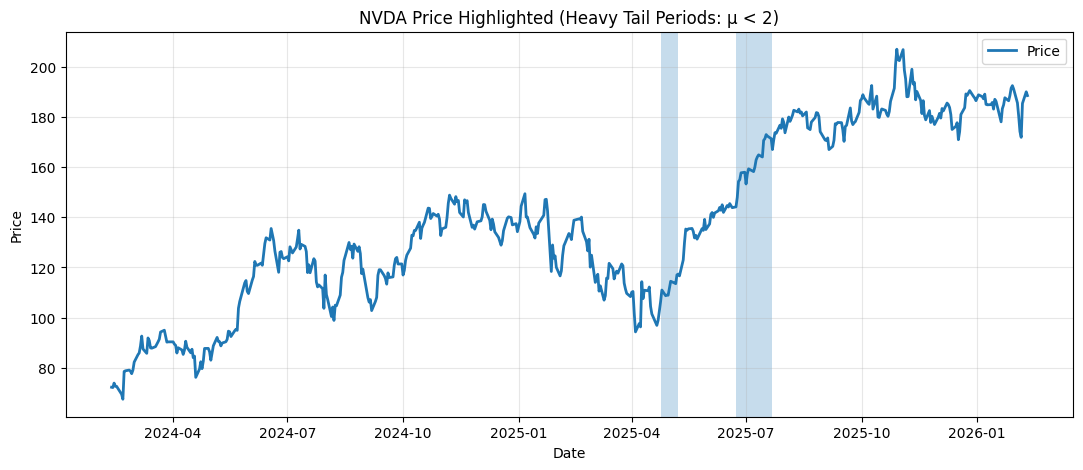

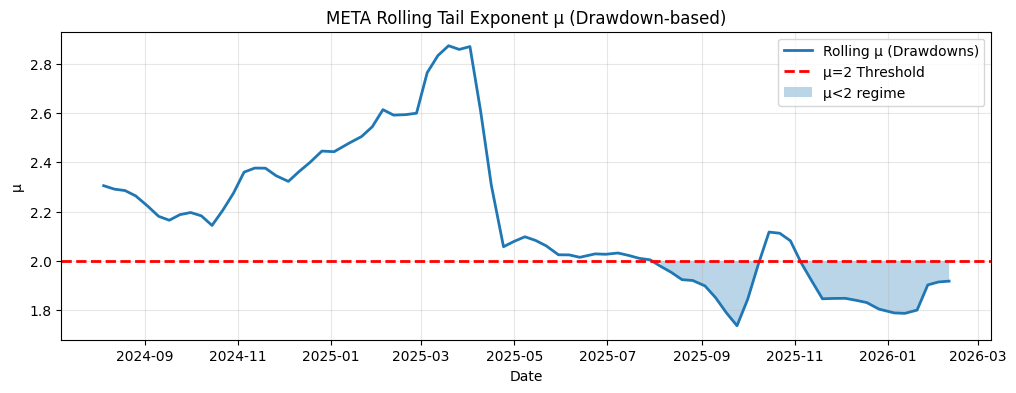

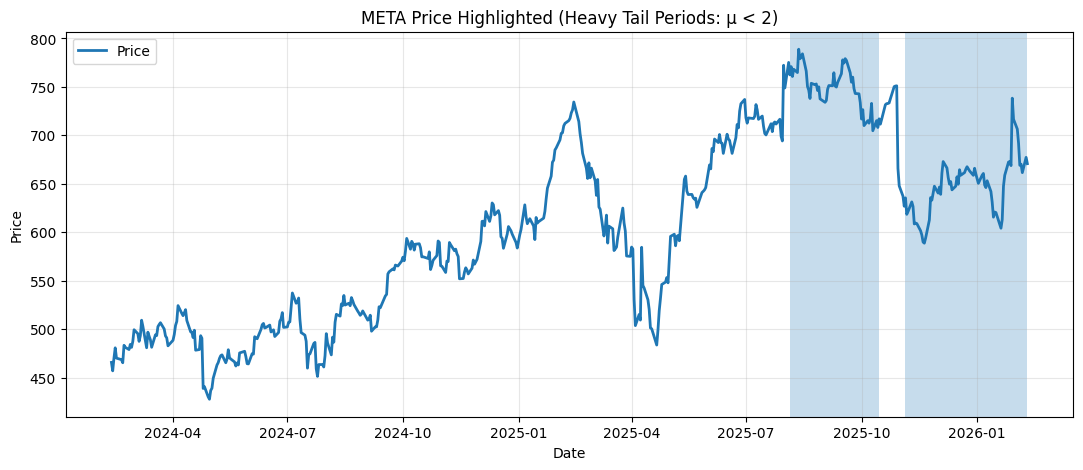

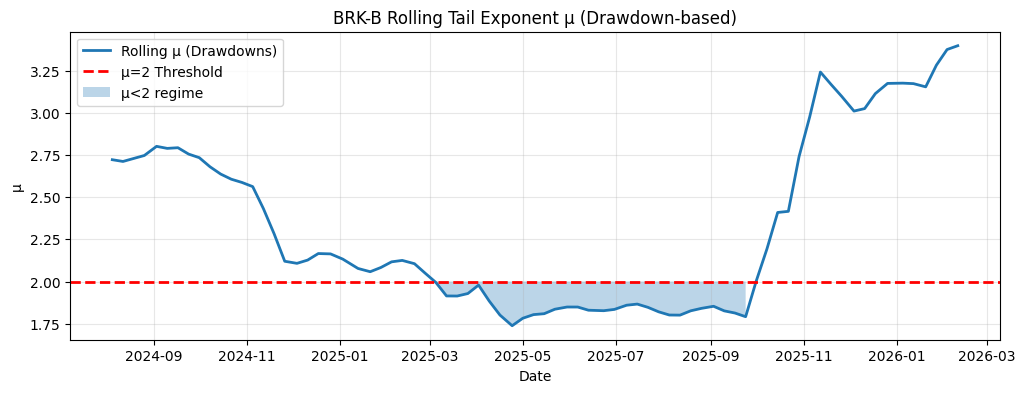

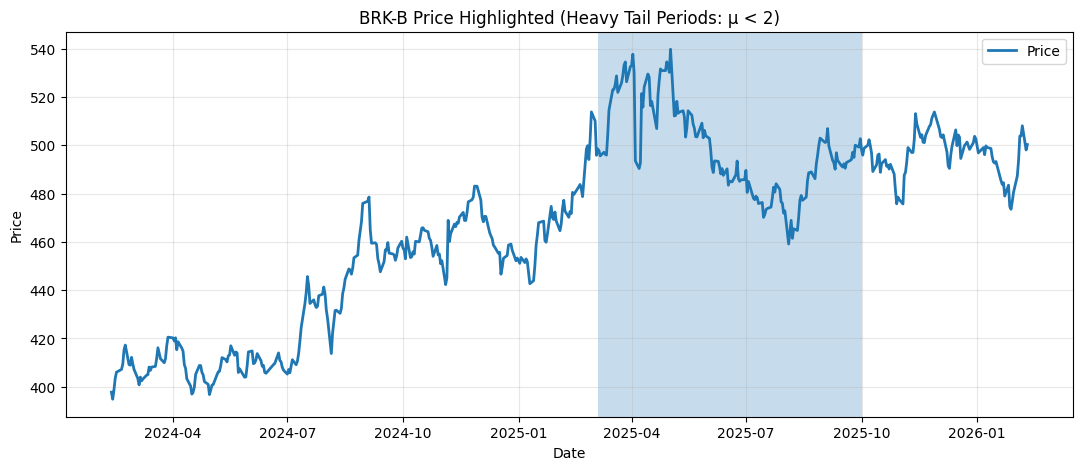

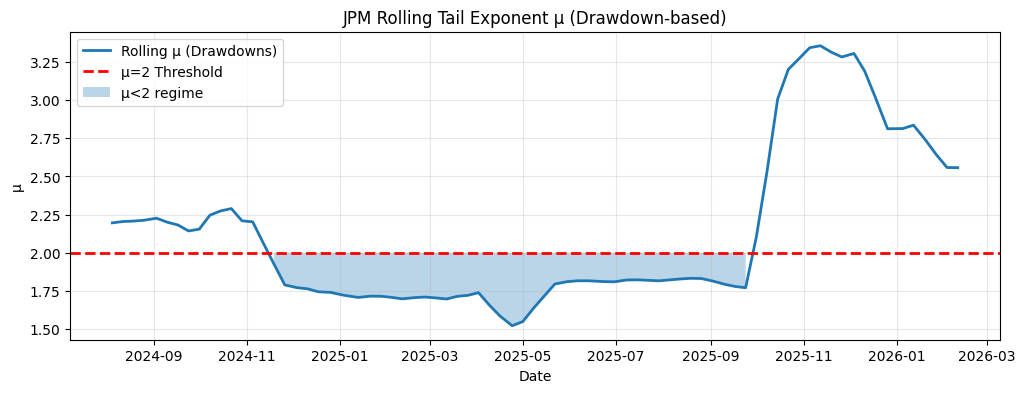

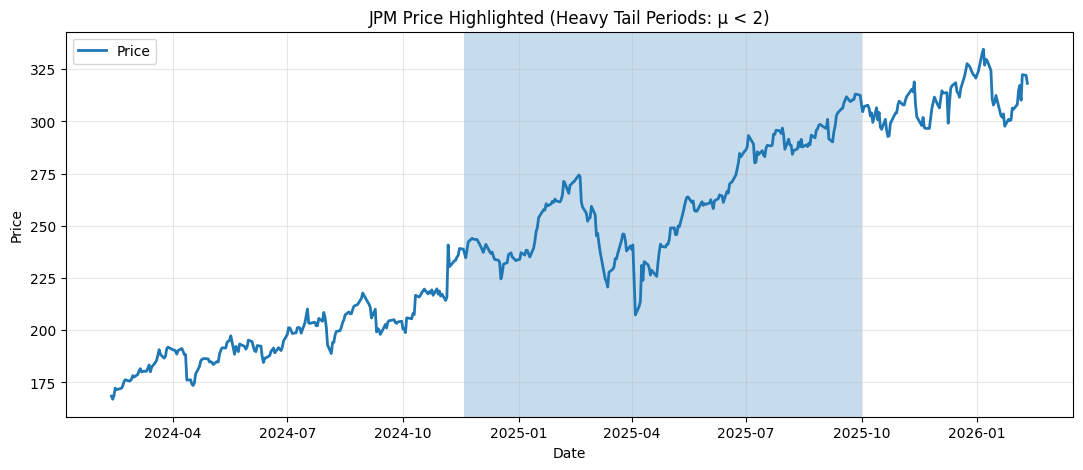

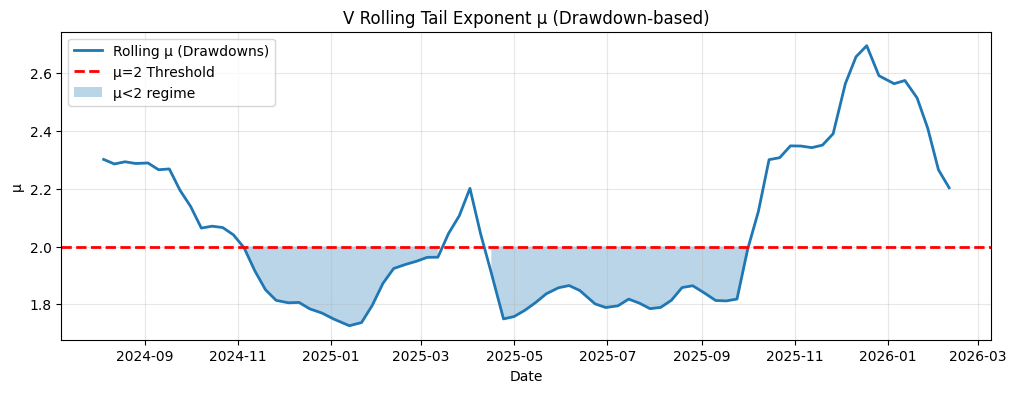

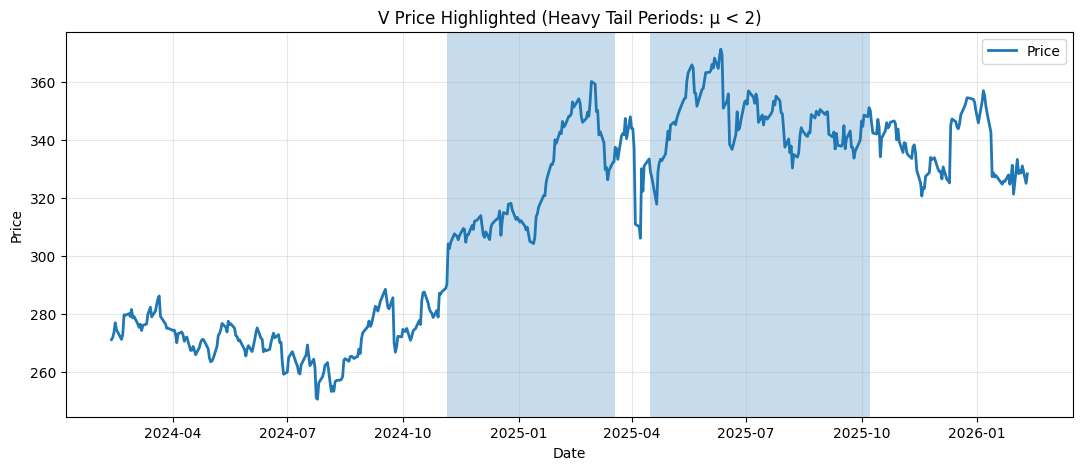

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
import yfinance as yf
import warnings

warnings.filterwarnings("ignore")

tickers = ["AAPL", "MSFT", "GOOGL", "AMZN", "TSLA", "NVDA", "META", "BRK-B", "JPM", "V"]

print("Downloading 2 years of data...")
data = yf.download(tickers, period="2y", progress=False)["Close"]

log_returns_df = np.log(data / data.shift(1)).dropna()
price_df = data.dropna()

print(f"Downloaded {len(log_returns_df)} return points.\n")


# -----------------------------
# Power-law µ estimator (CCDF)
# -----------------------------
def powerlaw_mu_ccdf(values, tail_fraction=0.30):

    x = np.abs(values)
    x = x[x > 0]

    if len(x) < 50:
        return np.nan

    x_sorted = np.sort(x)

    cutoff_index = int((1 - tail_fraction) * len(x_sorted))
    x_tail = x_sorted[cutoff_index:]

    if len(x_tail) < 20:
        return np.nan

    ranks = np.arange(len(x_tail), 0, -1)
    ccdf = ranks / len(x_tail)

    logx = np.log(x_tail)
    logccdf = np.log(ccdf)

    slope = linregress(logx, logccdf)[0]
    mu = -slope
    return mu


# -----------------------------
# Drawdown extractor (FAST)
# -----------------------------
def extract_drawdowns(prices):
    prices = np.array(prices)

    peak = prices[0]
    dd_list = []
    current_dd = 0

    for price in prices[1:]:
        if price >= peak:
            if current_dd < 0:
                dd_list.append(current_dd)
            peak = price
            current_dd = 0
        else:
            current_dd = (price - peak) / peak

    if current_dd < 0:
        dd_list.append(current_dd)

    return np.array(dd_list)


# -----------------------------
# Rolling µ computation
# -----------------------------
WINDOW = 120
STEP = 5
TAIL_FRACTION = 0.30

for ticker in tickers:

    r_series = log_returns_df[ticker].dropna()
    p_series = price_df[ticker].dropna()

    r_dates = r_series.index
    prices = p_series.values

    mu_values = []
    mu_dates = []

    for start in range(0, len(prices) - WINDOW, STEP):
        end = start + WINDOW

        # ---- KEY CHANGE: use drawdowns instead of daily returns ----
        window_prices = prices[start:end]
        drawdowns = extract_drawdowns(window_prices)

        # If too few drawdowns exist, fallback to return tail
        if len(drawdowns) < 30:
            window_returns = r_series.iloc[start:end].values
            mu = powerlaw_mu_ccdf(window_returns, tail_fraction=TAIL_FRACTION)
        else:
            mu = powerlaw_mu_ccdf(drawdowns, tail_fraction=TAIL_FRACTION)

        mu_values.append(mu)
        mu_dates.append(r_dates[end-1])


    mu_values = np.array(mu_values)
    mu_dates = pd.to_datetime(mu_dates)

    # Smooth µ slightly
    mu_smooth = pd.Series(mu_values).rolling(3, min_periods=1).mean().values

    # Heavy tail mask
    heavy_mask = mu_smooth < 2

    # -----------------------------
    # Plot 1: Rolling µ
    # -----------------------------
    plt.figure(figsize=(12,4))
    plt.plot(mu_dates, mu_smooth, label="Rolling µ (Drawdowns)", linewidth=2)
    plt.axhline(2, color="red", linestyle="--", linewidth=2, label="µ=2 Threshold")
    plt.fill_between(mu_dates, mu_smooth, 2, where=heavy_mask, alpha=0.3, label="µ<2 regime")
    plt.title(f"{ticker} Rolling Tail Exponent µ (Drawdown-based)")
    plt.xlabel("Date")
    plt.ylabel("µ")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

    # -----------------------------
    # Plot 2: Price with highlighted heavy-tail regimes
    # -----------------------------
    plt.figure(figsize=(13,5))
    plt.plot(p_series.index, p_series.values, linewidth=2, label="Price")

    # Highlight heavy-tail periods on price chart
    for j in range(len(mu_dates)-1):
        if heavy_mask[j]:
            plt.axvspan(mu_dates[j], mu_dates[j+1], alpha=0.25)

    plt.title(f"{ticker} Price Highlighted (Heavy Tail Periods: µ < 2)")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()


In [11]:
!pip install lppls

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ------------------------------- -------- 1.0/1.3 MB 16.7 MB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 4.5 MB/s eta 0:00:00



[notice] A new release of pip is available: 25.0.1 -> 26.0
[notice] To update, run: python.exe -m pip install --upgrade pip


Time shape : (5031,)
Price shape: (5031,)


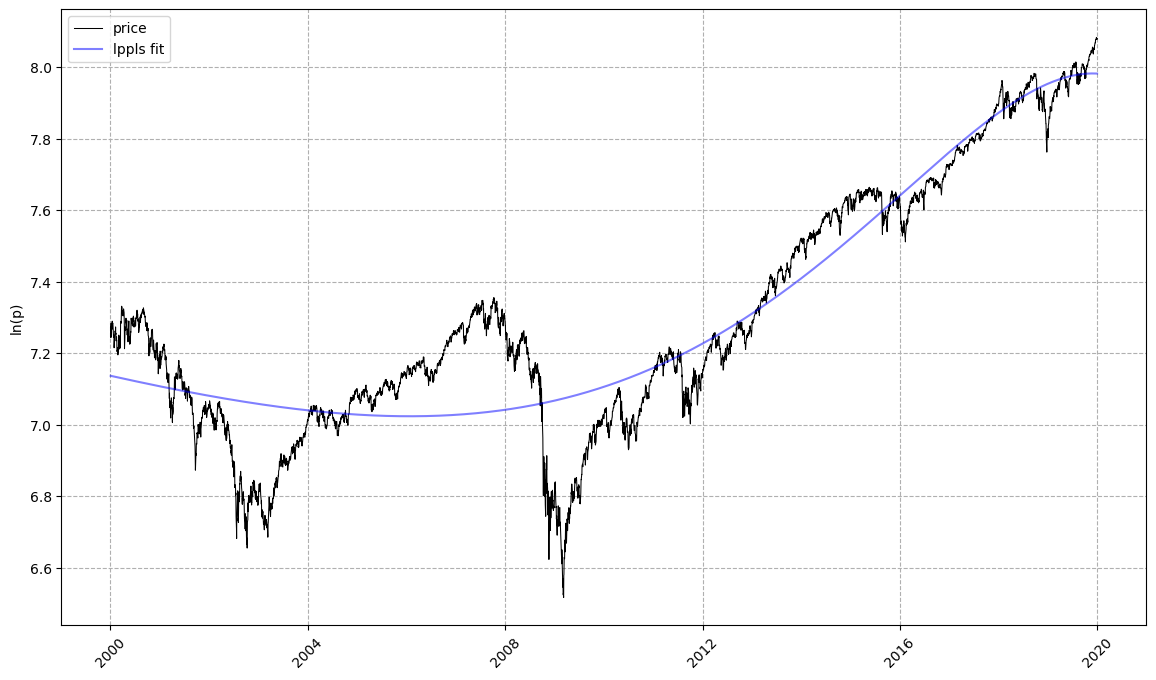

In [1]:
from lppls import lppls
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

%matplotlib inline


# -----------------------------
# Download data
# -----------------------------

ticker = "^GSPC"        # S&P 500
start = "2000-01-01"
end   = "2020-01-01"

df = yf.download(
    ticker,
    start=start,
    end=end,
    progress=False,
    auto_adjust=False
)


# -----------------------------
# Fix MultiIndex if exists
# -----------------------------

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)


# -----------------------------
# Keep only Adjusted Close
# -----------------------------

if "Adj Close" in df.columns:
    df = df[["Adj Close"]]
    price_col = "Adj Close"
else:
    df = df[["Close"]]
    price_col = "Close"


# -----------------------------
# Clean data
# -----------------------------

df = df.dropna()
df = df.reset_index()


# -----------------------------
# Prepare LPPLS inputs
# -----------------------------

# Dates → ordinal
time = df["Date"].apply(pd.Timestamp.toordinal).to_numpy()

# Log prices → FLATTENED
price = np.log(df[price_col].to_numpy().astype(float))


# -----------------------------
# Debug (important)
# -----------------------------

print("Time shape :", time.shape)
print("Price shape:", price.shape)


# -----------------------------
# Stack correctly
# -----------------------------

observations = np.vstack((time, price))


# -----------------------------
# Fit LPPLS
# -----------------------------

MAX_SEARCHES = 25

lppls_model = lppls.LPPLS(observations=observations)

tc, m, w, a, b, c, c1, c2, O, D = lppls_model.fit(MAX_SEARCHES)


# -----------------------------
# Plot
# -----------------------------

lppls_model.plot_fit()
plt.show()


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_11104\1971847799.py:81: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=pd.Timestamp.now() - pd.Timedelta(days=600), progress=False)



==================== REGIME SCAN: HINDCOPPER.NS ====================
Tested As Of: 2026-01-13
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
120 days     | 2026-01-13         | 0.350   | 6.896
80 days     | 2026-02-03         | 0.050   | 5.000
60 days     | 2026-01-29         | 0.050   | 5.004
30 days     | 2026-01-22         | 0.050   | 5.000


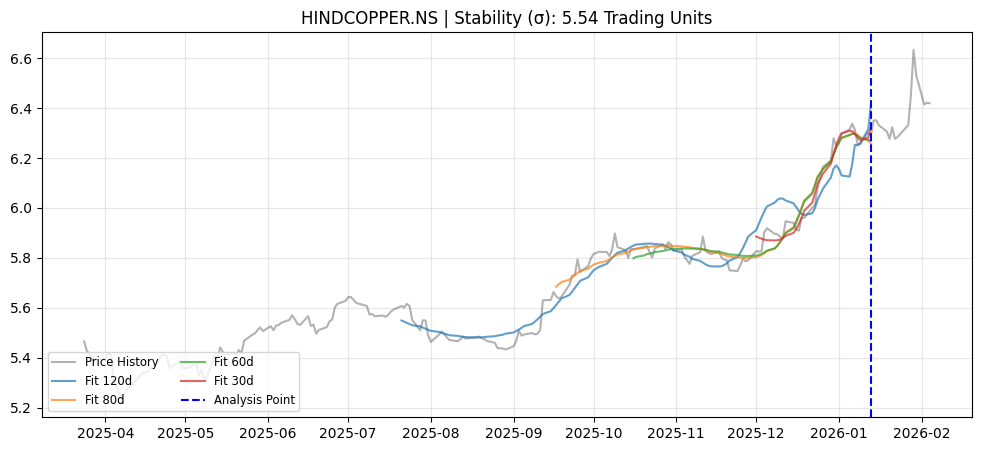

Consensus Stability Index: 5.54 (lower is more critical)
--------------------------------------------------------------------------------

==================== REGIME SCAN: VEDL.NS ====================
Tested As Of: 2026-01-13
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
120 days     | 2026-01-14         | 0.386   | 5.000
80 days     | 2026-01-13         | 0.450   | 5.280
60 days     | 2026-01-13         | 0.450   | 5.601
30 days     | 2026-01-21         | 0.450   | 5.005


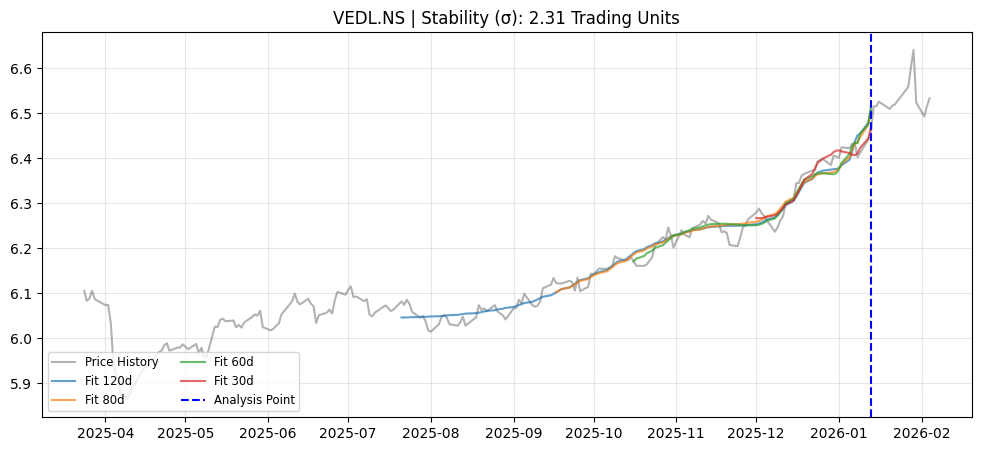

Consensus Stability Index: 2.31 (lower is more critical)
--------------------------------------------------------------------------------

==================== REGIME SCAN: HINDZINC.NS ====================
Tested As Of: 2026-01-13
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
120 days     | 2026-01-13         | 0.224   | 5.151
80 days     | 2026-01-26         | 0.450   | 5.000
60 days     | 2026-01-26         | 0.450   | 5.000
30 days     | 2026-01-23         | 0.450   | 5.000


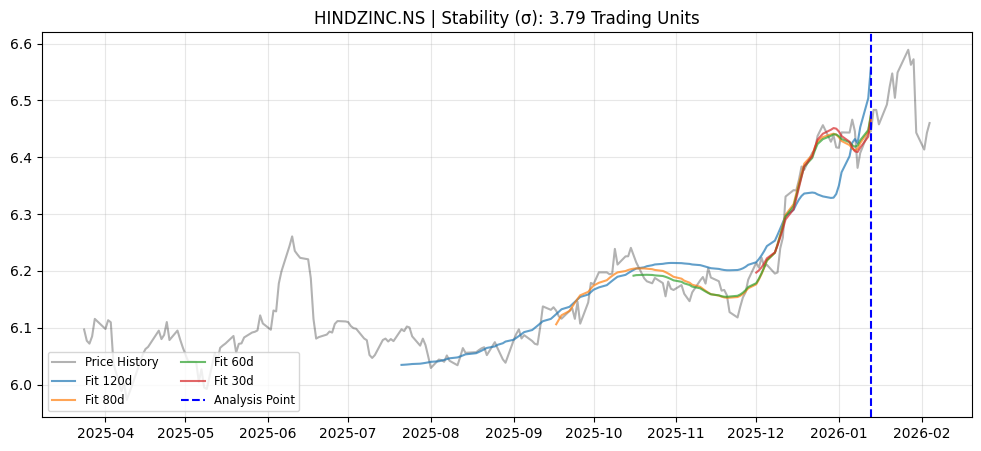

Consensus Stability Index: 3.79 (lower is more critical)
--------------------------------------------------------------------------------

==================== REGIME SCAN: TATASTEEL.NS ====================
Tested As Of: 2026-01-13
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
120 days     | 2026-01-13         | 0.450   | 5.000
80 days     | 2026-01-13         | 0.357   | 5.000
60 days     | 2026-01-13         | 0.333   | 6.080
30 days     | 2026-01-14         | 0.449   | 14.227


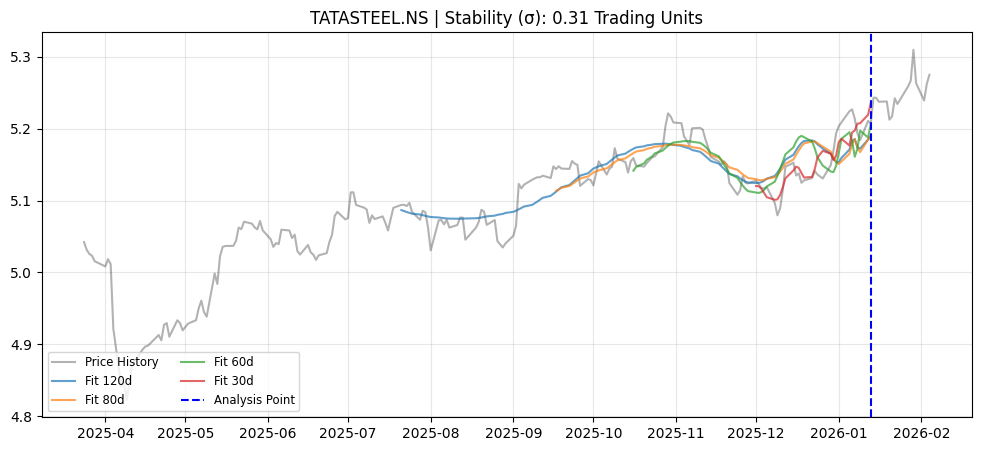

Consensus Stability Index: 0.31 (lower is more critical)
--------------------------------------------------------------------------------

==================== REGIME SCAN: GC=F ====================
Tested As Of: 2026-01-13
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
120 days     | 2026-01-13         | 0.450   | 5.000
80 days     | 2026-01-13         | 0.450   | 11.865
60 days     | 2026-01-13         | 0.450   | 7.653
30 days     | 2026-01-13         | 0.321   | 5.360


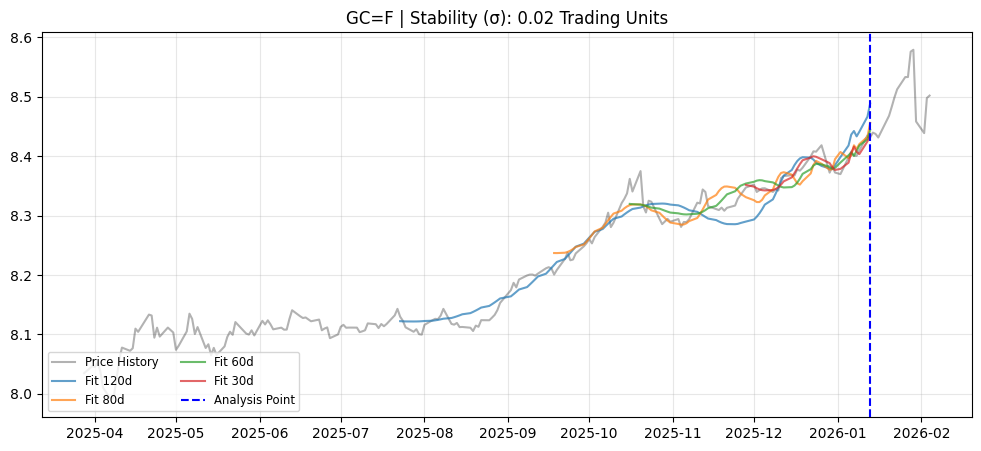

Consensus Stability Index: 0.02 (lower is more critical)
--------------------------------------------------------------------------------

==================== REGIME SCAN: NVDA ====================
Tested As Of: 2026-01-12
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
120 days     | 2026-01-12         | 0.347   | 5.587
80 days     | 2026-01-12         | 0.050   | 13.560
60 days     | 2026-01-15         | 0.100   | 6.000
30 days     | 2026-01-12         | 0.450   | 8.447


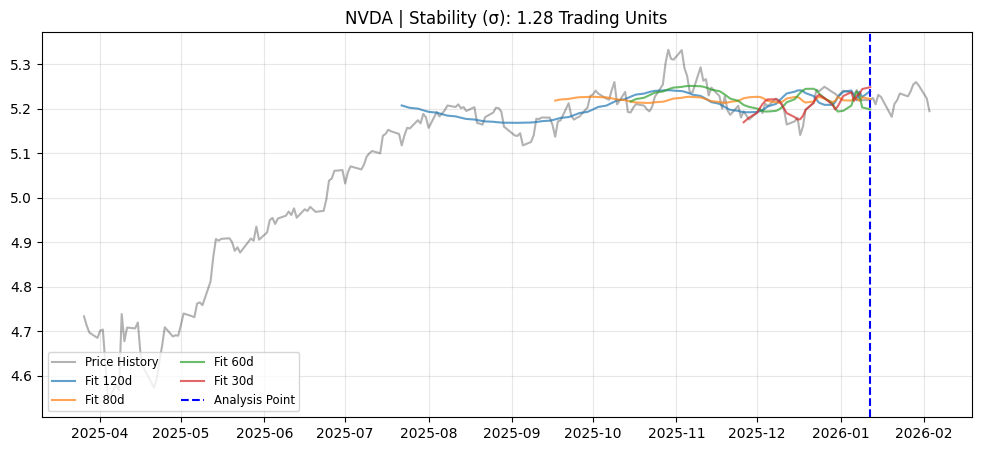

Consensus Stability Index: 1.28 (lower is more critical)
--------------------------------------------------------------------------------


In [6]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from numba import njit

# -----------------------------
# 1. Dragon King Parameters
# -----------------------------
tickers = ["HINDCOPPER.NS", "VEDL.NS", "HINDZINC.NS", "TATASTEEL.NS", "GC=F", "NVDA"]
window_start_offsets = [120, 80, 60, 30] 
lookback_offset = 15 
plot_duration = 200

# ... [njit functions solve_lppl, cost_fn, and fit_sornette_model stay the same] ...

@njit
def solve_lppl(tc, m, w, t, p):
    tau = np.maximum(tc - t, 1e-4)
    log_tau = np.log(tau)
    f, g, h = tau**m, tau**m * np.cos(w * log_tau), tau**m * np.sin(w * log_tau)
    X = np.ones((len(t), 4))
    X[:, 1], X[:, 2], X[:, 3] = f, g, h
    sol, _, _, _ = np.linalg.lstsq(X, p)
    return sol, f, g, h

@njit
def cost_fn(params, t, p):
    tc, m, w = params
    # 1. STRICTER PHYSICAL BOUNDS
    # tc must be within a reasonable horizon (max 45 trading days out)
    if tc <= t[-1] or tc > t[-1] + 30: return 1e22
    if m < 0.05 or m > 0.45: return 1e22 # Strict bubble acceleration
    if w < 5.0 or w > 15.0: return 1e22
    
    lin, f, g, h = solve_lppl(tc, m, w, t, p)
    
    # 2. THE SORNETTE CONDITION (B < 0)
    if lin[1] >= 0: return 1e22 
    
    # 3. AMPLITUDE PENALTY
    # Oscillation magnitude (C) shouldn't overwhelm the growth (B)
    osc_amp = np.sqrt(lin[2]**2 + lin[3]**2)
    if osc_amp > abs(lin[1]): return 1e22

    y_hat = lin[0] + lin[1]*f + lin[2]*g + lin[3]*h
    mse = np.sum((y_hat - p)**2) / len(t)
    
    # 4. DISTANCE PENALTY (Prevents the 'May 2026' drift)
    # Penalizes dates too far from the current window's perspective
    dist_penalty = (tc - t[-1]) / 5.0
    return mse * (1.0 + dist_penalty)

def fit_sornette_model(t, p):
    tc_start = t[-1] + 1
    best_c = 1e30
    best_init = [tc_start + 5, 0.2, 8.0]
    
    # 5. DENSE GRID SEARCH (Acts like Differential Evolution's population)
    # We test 45 combinations before starting Nelder-Mead
    tcs = np.linspace(tc_start + 2, tc_start + 30, 5)
    ms = [0.1, 0.3, 0.5]
    ws = [6.0, 10.0, 14.0]
    
    for tc_g in tcs:
        for m_g in ms:
            for w_g in ws:
                c = cost_fn(np.array([tc_g, m_g, w_g]), t, p)
                if c < best_c:
                    best_c = c
                    best_init = [tc_g, m_g, w_g]
    
    # POLISH: Use the best of the 45 points as the seed
    res = minimize(cost_fn, best_init, args=(t, p), method='Nelder-Mead', tol=1e-9)
    return res.x

# -----------------------------
# 3. Running Window Analysis
# -----------------------------
data = yf.download(tickers, start=pd.Timestamp.now() - pd.Timedelta(days=600), progress=False)

for ticker in tickers:
    prices = data['Close'][ticker].dropna() if len(tickers) > 1 else data['Close'].dropna()
    df = prices.to_frame(name='Close').reset_index()
    
    end_idx = len(df) - 1 - lookback_offset
    if end_idx < max(window_start_offsets): continue
    
    as_of_date = df["Date"].iloc[end_idx]
    tc_trading_deltas = [] 
    
    print(f"\n{'='*20} REGIME SCAN: {ticker} {'='*20}")
    print(f"Tested As Of: {as_of_date.date()}")
    print(f"{'Window':<12} | {'tc (Calendar Date)':<20} | {'m':<8} | {'w':<8}")
    print("-" * 75)

    plt.figure(figsize=(12, 5))
    # Extend future view to 30 days to see the predicted peak
    limit = min(len(df)-1, end_idx + 30)
    view_df = df.iloc[max(0, end_idx - plot_duration) : limit + 1]
    plt.plot(view_df["Date"], np.log(view_df["Close"]), color="black", alpha=0.3, label="Price History")

    for start_offset in window_start_offsets:
        df_fit = df.iloc[end_idx - start_offset : end_idx + 1].copy()
        t_f = np.arange(len(df_fit)).astype(np.float64)
        p_f = np.log(df_fit["Close"].values).astype(np.float64)
        
        tc_rel, m, w = fit_sornette_model(t_f, p_f)
        diff_units = tc_rel - t_f[-1]
        tc_trading_deltas.append(diff_units)
        
        # BIAS FIX: Use BusinessDay offset for the printed date
        tc_calendar_date = as_of_date + pd.tseries.offsets.BusinessDay(n=int(round(diff_units)))
        
        lin_f, f_v, g_v, h_v = solve_lppl(tc_rel, m, w, t_f, p_f)
        y_fit = lin_f[0] + lin_f[1]*f_v + lin_f[2]*g_v + lin_f[3]*h_v
        plt.plot(df_fit["Date"], y_fit, alpha=0.7, label=f"Fit {start_offset}d")
        
        print(f"{start_offset} days     | {tc_calendar_date.date()}         | {m:.3f}   | {w:.3f}")

    stability_sigma = np.std(tc_trading_deltas)
    plt.axvline(as_of_date, color="blue", ls="--", label="Analysis Point")
    plt.title(f"{ticker} | Stability (σ): {stability_sigma:.2f} Trading Units")
    plt.legend(loc='lower left', fontsize='small', ncol=2); plt.grid(alpha=0.3); plt.show()
    
    print(f"Consensus Stability Index: {stability_sigma:.2f} (lower is more critical)")
    print("-" * 80)


==================== 2008 REGIME SCAN: ^GSPC ====================
Pivot Date: 2008-09-26
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
100 days     | 2008-10-01         | 0.100   | 6.000
80 days     | 2008-10-01         | 0.100   | 6.000
60 days     | 2008-10-01         | 0.100   | 6.000
30 days     | 2008-10-01         | 0.100   | 6.000


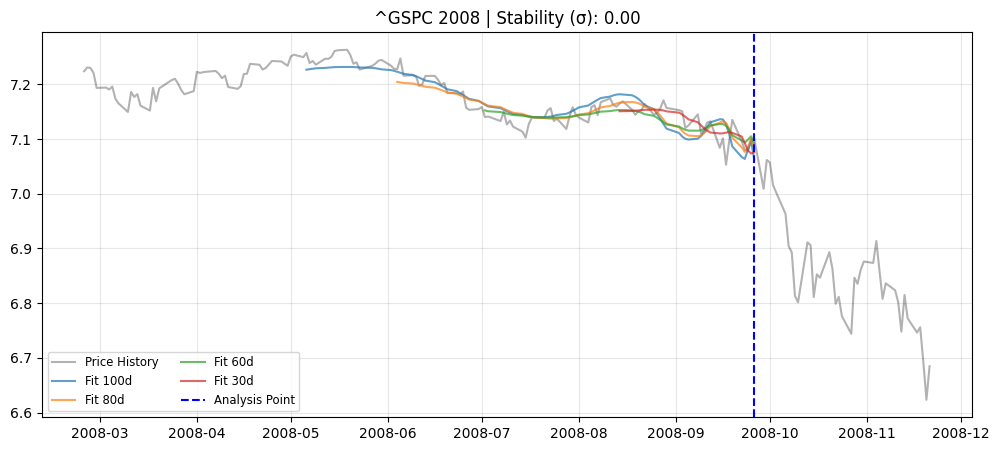

Consensus Stability Index: 0.00
--------------------------------------------------------------------------------

==================== 2008 REGIME SCAN: JPM ====================
Pivot Date: 2008-09-26
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
100 days     | 2008-09-26         | 0.139   | 6.579
80 days     | 2008-09-26         | 0.188   | 8.928
60 days     | 2008-09-26         | 0.224   | 5.858
30 days     | 2008-09-26         | 0.207   | 14.529


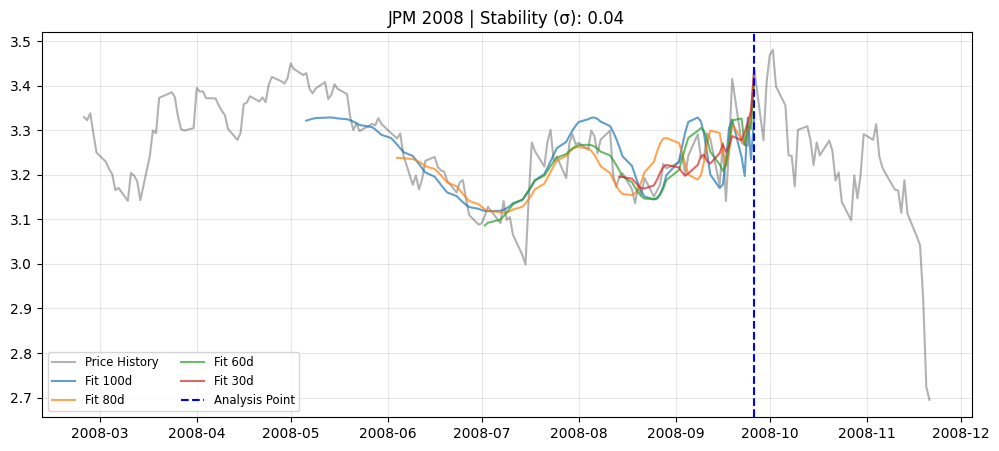

Consensus Stability Index: 0.04
--------------------------------------------------------------------------------

==================== 2008 REGIME SCAN: XLF ====================
Pivot Date: 2008-09-26
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
100 days     | 2008-10-01         | 0.100   | 6.000
80 days     | 2008-10-01         | 0.100   | 6.000
60 days     | 2008-09-26         | 0.166   | 6.237
30 days     | 2008-09-26         | 0.050   | 14.456


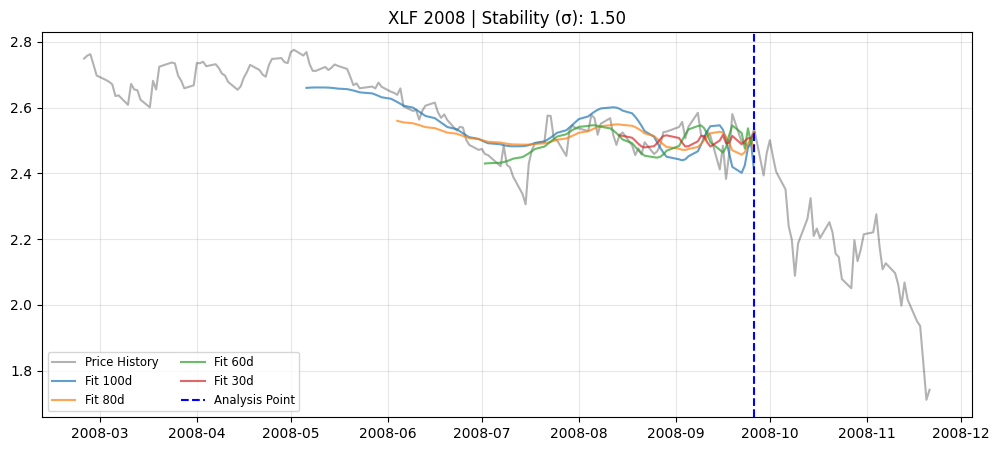

Consensus Stability Index: 1.50
--------------------------------------------------------------------------------

==================== 2008 REGIME SCAN: C ====================
Pivot Date: 2008-09-26
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
100 days     | 2008-10-01         | 0.100   | 6.000
80 days     | 2008-09-26         | 0.149   | 9.190
60 days     | 2008-09-26         | 0.145   | 5.942
30 days     | 2008-10-01         | 0.050   | 6.043


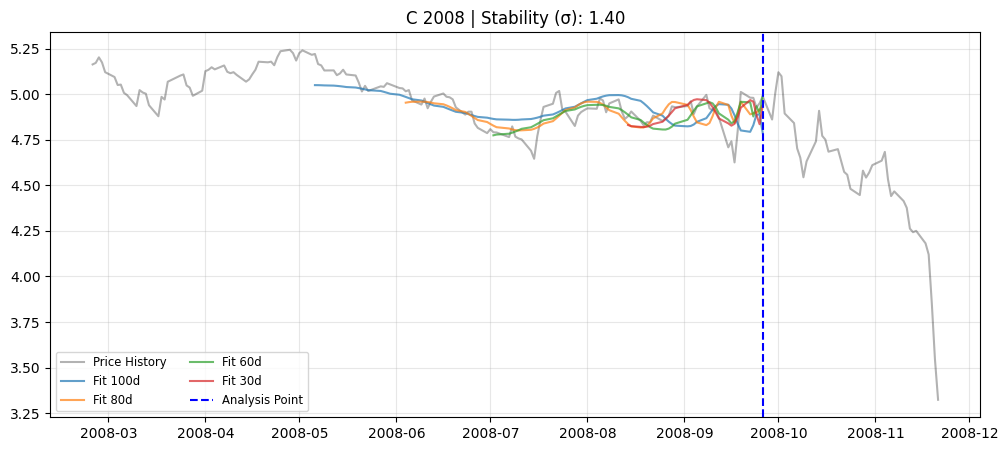

Consensus Stability Index: 1.40
--------------------------------------------------------------------------------

==================== 2008 REGIME SCAN: GE ====================
Pivot Date: 2008-09-26
Window       | tc (Calendar Date)   | m        | w       
---------------------------------------------------------------------------
100 days     | 2008-10-01         | 0.100   | 6.000
80 days     | 2008-10-01         | 0.100   | 6.000
60 days     | 2008-10-01         | 0.100   | 6.000
30 days     | 2008-10-01         | 0.100   | 6.000


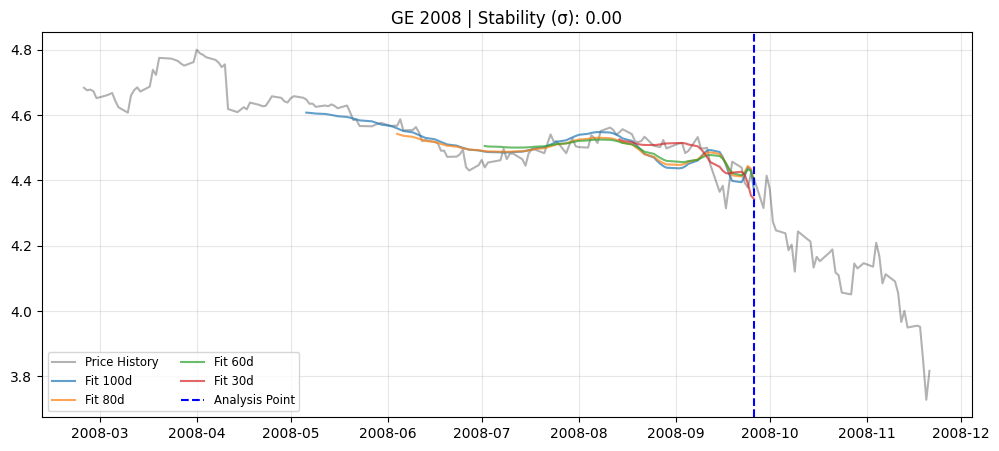

Consensus Stability Index: 0.00
--------------------------------------------------------------------------------


In [13]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from numba import njit

# -----------------------------
# 1. 2008 Configuration
# -----------------------------
tickers = ["^GSPC", "JPM" , "XLF", "C", "GE"] 
START_DATA = "2007-01-01"
END_DATA = "2009-06-01" 
TARGET_DATE = "2008-09-28" # Pivot before the Lehman crash
window_start_offsets = [100, 80, 60, 30] 
lookback_offset = 15 
plot_duration = 150

# -----------------------------
# 2. Mathematical Core (Your Strategy)
# -----------------------------
@njit
def solve_lppl(tc, m, w, t, p):
    tau = np.maximum(tc - t, 1e-4)
    log_tau = np.log(tau)
    f, g, h = tau**m, tau**m * np.cos(w * log_tau), tau**m * np.sin(w * log_tau)
    X = np.ones((len(t), 4))
    X[:, 1], X[:, 2], X[:, 3] = f, g, h
    sol, _, _, _ = np.linalg.lstsq(X, p)
    return sol, f, g, h

@njit
def cost_fn(params, t, p):
    tc, m, w = params
    # 1. STRICTER PHYSICAL BOUNDS
    if tc <= t[-1] or tc > t[-1] + 30: return 1e22
    if m < 0.05 or m > 0.45: return 1e22 
    if w < 5.0 or w > 15.0: return 1e22
    
    lin, f, g, h = solve_lppl(tc, m, w, t, p)
    
    # 2. THE SORNETTE CONDITION (B < 0)
    if lin[1] >= 0: return 1e22 
    
    # 3. AMPLITUDE PENALTY
    osc_amp = np.sqrt(lin[2]**2 + lin[3]**2)
    if osc_amp > abs(lin[1]): return 1e22

    y_hat = lin[0] + lin[1]*f + lin[2]*g + lin[3]*h
    mse = np.sum((y_hat - p)**2) / len(t)
    
    # 4. DISTANCE PENALTY
    dist_penalty = (tc - t[-1]) / 5.0
    return mse * (1.0 + dist_penalty)

def fit_sornette_model(t, p):
    tc_start = t[-1] + 1
    best_c = 1e30
    best_init = [tc_start + 5, 0.2, 8.0]
    
    # 5. DENSE GRID SEARCH
    tcs = np.linspace(tc_start + 2, tc_start + 30, 5)
    ms = [0.1, 0.3, 0.5]
    ws = [6.0, 10.0, 14.0]
    
    for tc_g in tcs:
        for m_g in ms:
            for w_g in ws:
                c = cost_fn(np.array([tc_g, m_g, w_g]), t, p)
                if c < best_c:
                    best_c = c
                    best_init = [tc_g, m_g, w_g]
    
    res = minimize(cost_fn, best_init, args=(t, p), method='Nelder-Mead', tol=1e-9)
    return res.x

# -----------------------------
# 3. Execution
# -----------------------------
data = yf.download(tickers, start=START_DATA, end=END_DATA, progress=False, auto_adjust=True)

for ticker in tickers:
    prices = data['Close'][ticker].dropna() if len(tickers) > 1 else data['Close'].dropna()
    df = prices.to_frame(name='Close').reset_index()
    
    try:
        end_idx = df[df['Date'] <= TARGET_DATE].index[-1]
    except: continue
    
    as_of_date = df["Date"].iloc[end_idx]
    tc_trading_deltas = [] 
    
    print(f"\n{'='*20} 2008 REGIME SCAN: {ticker} {'='*20}")
    print(f"Pivot Date: {as_of_date.date()}")
    print(f"{'Window':<12} | {'tc (Calendar Date)':<20} | {'m':<8} | {'w':<8}")
    print("-" * 75)

    plt.figure(figsize=(12, 5))
    limit = min(len(df)-1, end_idx + 40)
    view_df = df.iloc[max(0, end_idx - plot_duration) : limit + 1]
    plt.plot(view_df["Date"], np.log(view_df["Close"]), color="black", alpha=0.3, label="Price History")

    for start_offset in window_start_offsets:
        if end_idx - start_offset < 0: continue
        df_fit = df.iloc[end_idx - start_offset : end_idx + 1].copy()
        t_f = np.arange(len(df_fit)).astype(np.float64)
        p_f = np.log(df_fit["Close"].values).astype(np.float64)
        
        tc_rel, m, w = fit_sornette_model(t_f, p_f)
        diff_units = tc_rel - t_f[-1]
        tc_trading_deltas.append(diff_units)
        
        tc_calendar_date = as_of_date + pd.tseries.offsets.BusinessDay(n=int(round(diff_units)))
        
        lin_f, f_v, g_v, h_v = solve_lppl(tc_rel, m, w, t_f, p_f)
        y_fit = lin_f[0] + lin_f[1]*f_v + lin_f[2]*g_v + lin_f[3]*h_v
        plt.plot(df_fit["Date"], y_fit, alpha=0.7, label=f"Fit {start_offset}d")
        
        print(f"{start_offset} days     | {tc_calendar_date.date()}         | {m:.3f}   | {w:.3f}")

    stability_sigma = np.std(tc_trading_deltas)
    plt.axvline(as_of_date, color="blue", ls="--", label="Analysis Point")
    plt.title(f"{ticker} 2008 | Stability (σ): {stability_sigma:.2f}")
    plt.legend(loc='lower left', fontsize='small', ncol=2); plt.grid(alpha=0.3); plt.show()
    
    print(f"Consensus Stability Index: {stability_sigma:.2f}")
    print("-" * 80)